## Análisis de Datos Meteorológicos con una API Pública
Obtener datos del clima de una ciudad usando la API de Open-Meteo (https://open-meteo.com/) y mostrar el pronóstico para Bilbao.

* Haz una petición a la API para que devuelva el pronóstico de las temperaturas para una semana en Bilbao. Tip: el parámetro correspondiente en el query es `temperature_2m` además de la latitud y la longitud.
* Procesa la respuesta en formato JSON para obtener dos listas: una con la lista de temperaturas y otra con las fechas-horas correspondientes.
* Crea un DataFrame con esas dos columnas: `Hora` y `Temperatura`
* Elige la gráfica adecuada y visualiza el pronóstico de temperaturas.

Para crear la variable `Hora` del DataFrame puedes introducir directamente la lista que se obtiene del campo `data["hourly"]["time"]` o procesar esa lista mediante el siguiente código:

`hours = pd.date_range(start=lista_de_horas, periods=len(temps), freq="H")`

In [3]:
import requests


# Coordenadas de Kuna en Bilbao
latitude = 43.2540
longitude = -2.9230


url = f"https://api.open-meteo.com/v1/forecast?"  # Aquí vienen el resto de los parámetros

In [4]:
%pip install requests



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [6]:
# Definimos los parámetros de la petición
params = {
    "latitude": latitude,
    "longitude": longitude,
    "hourly": "temperature_2m",
    "forecast_days": 7
}

In [7]:
# Realizamos la petición a la API
response = requests.get(url, params=params)

# Comprobamos el estado de la respuesta
response.status_code

200

In [8]:
# Convertimos la respuesta de la API al formato JSON
data = response.json()

# Mostramos los datos recibidos
data

{'latitude': 43.25,
 'longitude': -2.92,
 'generationtime_ms': 0.07891654968261719,
 'utc_offset_seconds': 0,
 'timezone': 'GMT',
 'timezone_abbreviation': 'GMT',
 'elevation': 14.0,
 'hourly_units': {'time': 'iso8601', 'temperature_2m': '°C'},
 'hourly': {'time': ['2026-11-09T00:00',
   '2026-11-09T01:00',
   '2026-11-09T02:00',
   '2026-11-09T03:00',
   '2026-11-09T04:00',
   '2026-11-09T05:00',
   '2026-11-09T06:00',
   '2026-11-09T07:00',
   '2026-11-09T08:00',
   '2026-11-09T09:00',
   '2026-11-09T10:00',
   '2026-11-09T11:00',
   '2026-11-09T12:00',
   '2026-11-09T13:00',
   '2026-11-09T14:00',
   '2026-11-09T15:00',
   '2026-11-09T16:00',
   '2026-11-09T17:00',
   '2026-11-09T18:00',
   '2026-11-09T19:00',
   '2026-11-09T20:00',
   '2026-11-09T21:00',
   '2026-11-09T22:00',
   '2026-11-09T23:00',
   '2026-11-10T00:00',
   '2026-11-10T01:00',
   '2026-11-10T02:00',
   '2026-11-10T03:00',
   '2026-11-10T04:00',
   '2026-11-10T05:00',
   '2026-11-10T06:00',
   '2026-11-10T07:00',
 

In [9]:
# Obtenemos la lista de temperaturas
temps = data["hourly"]["temperature_2m"]

# Obtenemos la lista de fechas y horas
lista_de_horas = data["hourly"]["time"]

# Mostramos los primeros cinco valores
print(temps[:5])
print(lista_de_horas[:5])

[18.8, 18.4, 19.4, 19.5, 19.9]
['2026-11-09T00:00', '2026-11-09T01:00', '2026-11-09T02:00', '2026-11-09T03:00', '2026-11-09T04:00']


In [10]:
# Importamos la librería Pandas para trabajar con datos
import pandas as pd

In [11]:
# Creamos un DataFrame con las fechas y las temperaturas
df = pd.DataFrame({
    "Hora": lista_de_horas,
    "Temperatura": temps
})

# Convertimos la columna Hora al formato datetime
df["Hora"] = pd.to_datetime(df["Hora"])

# Mostramos las primeras filas del DataFrame
df.head()

,Hora,Temperatura
0,2026-11-09 00:00:00,18.8
1,2026-11-09 01:00:00,18.4
2,2026-11-09 02:00:00,19.4
3,2026-11-09 03:00:00,19.5
4,2026-11-09 04:00:00,19.9


In [12]:
# Importamos la librería para crear gráficos
import matplotlib.pyplot as plt

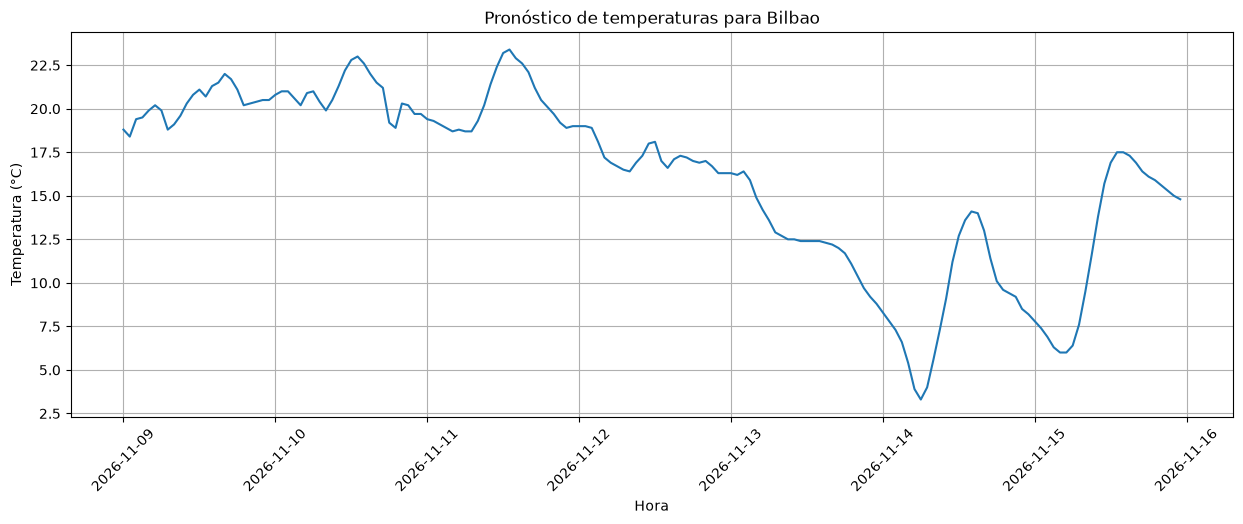

In [13]:
# Definimos el tamaño de la figura
plt.figure(figsize=(15, 5))

# Creamos un gráfico de líneas con las temperaturas
plt.plot(df["Hora"], df["Temperatura"])

# Añadimos el título del gráfico
plt.title("Pronóstico de temperaturas para Bilbao")

# Añadimos la etiqueta del eje X
plt.xlabel("Hora")

# Añadimos la etiqueta del eje Y
plt.ylabel("Temperatura (°C)")

# Rotamos las etiquetas del eje X para facilitar la lectura
plt.xticks(rotation=45)

# Añadimos una cuadrícula al gráfico
plt.grid()

# Mostramos el gráfico
plt.show()

In [14]:
# Mostramos información general del DataFrame
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 168 entries, 0 to 167
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Hora         168 non-null    datetime64[us]
 1   Temperatura  168 non-null    float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 2.8 KB


In [15]:
# Calculamos estadísticas descriptivas de las temperaturas
df.describe()

,Hora,Temperatura
count,168,168.000000
mean,2026-11-12 11:30:00,16.118452
min,2026-11-09 00:00:00,3.300000
25%,2026-11-10 17:45:00,12.475000
50%,2026-11-12 11:30:00,17.200000
75%,2026-11-14 05:15:00,20.200000
max,2026-11-15 23:00:00,23.400000
std,NaN,5.002702
